# Práctica 6 · Proceso de Análisis Jerárquico de Clasificación (AHPSort II)
**Sistemas de Ayuda a la Decisión · Universidad de Jaén**

**Autor:** Samuel Muñoz Millán

Clasificación de las provincias españolas en tres niveles de seguridad (**Alto**, **Medio** y **Bajo**) según sus datos de criminalidad, con el método **AHPSort II**, y representación de los resultados en mapas.

### Cómo ejecutarlo
- **Google Colab:** menú **Entorno de ejecución → Ejecutar todas**. La primera celda descarga los datos y los mapas del repositorio.
- **En local:** `pip install -r requirements.txt` y ejecutar el cuaderno con Jupyter desde la carpeta del repositorio.

El cuaderno ya está ejecutado y guardado con todas sus salidas, así que los resultados se pueden consultar sin ejecutarlo. Cada vez que se ejecuta, las tablas (CSV) y los mapas (PNG) se guardan también en la carpeta `resultados/`.

### Contenido
0. Preparación
1. Método AHPSort II (funciones)
2. Ejercicio 1: Andalucía con datos absolutos
3. Ejercicio 2: Andalucía con datos por cada 10.000 habitantes
4. Ejercicio 3: España (50 provincias), 2017
5. Ejercicio 4: España, 2023, con la calibración de 2017

## 0. Preparación
Si el cuaderno se ejecuta en Colab, descarga el repositorio con los datos y los mapas. Después carga las librerías.

In [1]:
# ============================================================
# 0. PREPARACIÓN
# ============================================================
import os, sys, subprocess, importlib.util, unicodedata
from fractions import Fraction

# librerías que podrían faltar (xlrd lee el fichero .xls de Andalucía)
for paquete in ['xlrd', 'openpyxl', 'geopandas']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete], check=True)

REPO = 'https://github.com/smmdev/SAD-P6-AHPSort'
if not os.path.isdir('datos'):                      # en Colab: se descarga el repositorio
    if not os.path.isdir('SAD-P6-AHPSort'):
        subprocess.run(['git', 'clone', '-q', REPO], check=True)
    os.chdir('SAD-P6-AHPSort')
os.makedirs('resultados', exist_ok=True)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import matplotlib.patheffects as efectos
from IPython.display import display, Markdown

CRITERIOS = ['Crímenes', 'Robos', 'Vehículos', 'Orden público', 'Drogas']
NIVELES = ['Alto', 'Medio', 'Bajo']                 # CP1, CP2 y CP3
COLORES = {'Alto': '#4caf50', 'Medio': '#ffc107', 'Bajo': '#e53935'}
print('Datos y librerías listos.')

Datos y librerías listos.


## 1. Método AHPSort II
- **Pesos de los criterios:** autovector del autovalor máximo de la matriz de comparación a pares, normalizado para que sume 1. Se comprueba la consistencia con CI = (λmax − n)/(n − 1) y CR = CI/RI (válida si CR < 0,1).
- **Puntos de referencia (RP):** 6 puntos a la misma distancia entre sí, desde 0 (RP1) hasta el valor máximo (RP6).
- **Perfiles centrales (CP):** el valor típico de cada nivel de seguridad. CP1 (nivel Alto) tiene pocos delitos, CP2 (nivel Medio) un valor intermedio y CP3 (nivel Bajo) muchos.
- **Función de prioridad local:** une con segmentos rectos los puntos (valor, prioridad) de cada criterio. La prioridad local de cualquier valor se obtiene por **interpolación lineal** entre los dos puntos que lo rodean. Si el valor queda fuera del rango, se **trunca** al extremo más cercano.
- **Prioridad global:** suma de los pesos de los criterios multiplicados por las prioridades locales.
- **Clasificación:** cada provincia se asigna al nivel cuyo perfil central tiene la prioridad global **más cercana** a la suya. Por eso, el límite entre dos niveles es el punto medio entre las prioridades globales de sus perfiles centrales.

In [2]:
# ============================================================
# 1. MÉTODO AHPSORT II
# ============================================================
RI = {1: 0, 2: 0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}


def pesos_ahp(matriz, nombres):
    """Pesos con el método de los autovalores y consistencia de la matriz."""
    A = np.array(matriz, dtype=float)
    n = len(A)
    autovalores, autovectores = np.linalg.eig(A)
    k = np.argmax(autovalores.real)                 # autovalor máximo
    lambda_max = autovalores[k].real
    vector = np.abs(autovectores[:, k].real)
    pesos = pd.Series(vector / vector.sum(), index=nombres, name='Peso')
    ci = (lambda_max - n) / (n - 1)
    cr = ci / RI[n]
    return pesos, lambda_max, ci, cr


def puntos_referencia(maximo, n=6):
    """n puntos repartidos por igual entre 0 y el máximo."""
    return np.linspace(0, maximo, n)


def perfiles_centrales(valores):
    """CP1, CP2 y CP3: percentiles 20, 50 y 80 de los datos."""
    return np.percentile(valores, [20, 50, 80])


def funcion(valores, prioridades, etiquetas):
    """Puntos (valor, prioridad) de una función de prioridad local, ordenados por valor."""
    f = pd.DataFrame({'Punto': etiquetas, 'Valor': valores, 'Prioridad': prioridades})
    return f.sort_values('Valor', kind='stable').reset_index(drop=True)


def prioridad_local(f, x):
    """Interpolación lineal en la función f. Fuera del rango se trunca al extremo."""
    return float(np.interp(x, f['Valor'], f['Prioridad']))


def clasificar(datos, pesos, funciones, cp_global):
    """Prioridades locales, prioridad global y nivel de seguridad de cada provincia."""
    tabla = pd.DataFrame({c: [prioridad_local(funciones[c], x) for x in datos[c]] for c in CRITERIOS},
                         index=datos.index)
    tabla['Global'] = (tabla[CRITERIOS] * pesos[CRITERIOS]).sum(axis=1)
    distancia = np.abs(tabla['Global'].to_numpy()[:, None] - np.array(cp_global)[None, :])
    tabla['Nivel de seguridad'] = [NIVELES[i] for i in distancia.argmin(axis=1)]
    return tabla


def tabla_perfiles(funciones, cps, pesos):
    """Prioridades locales y globales de los perfiles centrales."""
    t = pd.DataFrame({c: [prioridad_local(funciones[c], v) for v in cps[c]] for c in CRITERIOS},
                     index=[f'CP{i + 1} ({n})' for i, n in enumerate(NIVELES)])
    t['Global'] = (t[CRITERIOS] * pesos[CRITERIOS]).sum(axis=1)
    return t


def limites(cp_global):
    """Prioridades globales que separan los niveles (punto medio entre perfiles)."""
    return [(cp_global[0] + cp_global[1]) / 2, (cp_global[1] + cp_global[2]) / 2]


# ---------- Presentación ----------
# bordes y separación de las tablas (se ven igual con el tema claro y el oscuro)
ESTILO_TABLA = [
    {'selector': '', 'props': [('border-collapse', 'collapse'), ('margin-bottom', '12px')]},
    {'selector': 'th, td', 'props': [('border', '1px solid #8a8a8a'), ('padding', '4px 10px'),
                                     ('text-align', 'center')]},
    {'selector': 'th', 'props': [('font-weight', 'bold')]},
]


def mostrar(df, decimales=4, titulo=None):
    """Muestra una tabla con coma decimal y punto de miles."""
    if titulo:
        display(Markdown(f'**{titulo}**'))
    df = df.copy()
    reales = df.select_dtypes('float').columns
    df[reales] = df[reales].round(decimales) + 0.0          # evita que aparezca '-0,00'
    if df.index.name and df.columns.name is None:           # nombre del índice en la esquina
        df.columns.name, df.index.name = df.index.name, None
    display(df.style.format(precision=decimales, decimal=',', thousands='.').set_table_styles(ESTILO_TABLA))


def mostrar_funcion(f, titulo):
    """Puntos de una función de prioridad local: valores y prioridades (3 decimales)."""
    display(Markdown(f'**{titulo}**'))
    t = f.set_index('Punto').T
    estilo = (t.style.set_table_styles(ESTILO_TABLA)
              .format(lambda v: numero(round(v, 3)), subset=pd.IndexSlice[['Valor'], :])
              .format(precision=3, decimal=',', subset=pd.IndexSlice[['Prioridad'], :]))
    display(estilo)


def sin_tildes(texto):
    """Para ordenar alfabéticamente sin que las tildes alteren el orden."""
    return ''.join(ch for ch in unicodedata.normalize('NFD', texto) if unicodedata.category(ch) != 'Mn')


def numero(v, _=None):
    """Número con coma decimal y punto de miles (para los ejes de las gráficas)."""
    return format(v, ',.10g').translate(str.maketrans(',.', '.,'))


def dibujar_funciones(funciones, titulo, archivo):
    """Funciones de prioridad local: RPs en azul y CPs en rojo."""
    fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
    for eje, c in zip(ejes.flat, CRITERIOS):
        f = funciones[c]
        eje.plot(f['Valor'], f['Prioridad'], '-', color='#1f77b4')
        rp = f[f['Punto'].str.startswith('RP')]
        cp = f[f['Punto'].str.startswith('CP')]
        eje.plot(rp['Valor'], rp['Prioridad'], 'o', color='#1f77b4', label='RP')
        eje.plot(cp['Valor'], cp['Prioridad'], 'D', color='#d62728', label='CP')
        eje.set_title(c)
        eje.set_xlabel('Valor')
        eje.set_ylabel('Prioridad local')
        eje.grid(alpha=0.3)
        eje.xaxis.set_major_formatter(FuncFormatter(numero))
        eje.yaxis.set_major_formatter(FuncFormatter(numero))
    ejes.flat[-1].axis('off')
    ejes.flat[0].legend()
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    fig.savefig(f'resultados/{archivo}', dpi=150)
    plt.show()


def leyenda(eje, sin_datos=False):
    marcas = [Patch(facecolor=COLORES[n], edgecolor='black', label=n) for n in NIVELES]
    if sin_datos:
        marcas.append(Patch(facecolor='#d9d9d9', edgecolor='black', label='Sin datos'))
    eje.legend(handles=marcas, title='Nivel de seguridad', loc='lower right', fontsize=10)

In [3]:
# ---------- Mapas ----------
COD_PROVINCIA = {
    'Araba/Álava': '01', 'Albacete': '02', 'Alicante/Alacant': '03', 'Almería': '04', 'Ávila': '05',
    'Badajoz': '06', 'Balears (Illes)': '07', 'Balears, Illes': '07', 'Barcelona': '08', 'Burgos': '09',
    'Cáceres': '10', 'Cádiz': '11', 'Castellón/Castelló': '12', 'Ciudad Real': '13', 'Córdoba': '14',
    'Coruña (A)': '15', 'Coruña, A': '15', 'Cuenca': '16', 'Girona': '17', 'Granada': '18',
    'Guadalajara': '19', 'Gipuzkoa': '20', 'Huelva': '21', 'Huesca': '22', 'Jaén': '23', 'León': '24',
    'Lleida': '25', 'Rioja (La)': '26', 'Rioja, La': '26', 'Lugo': '27', 'Madrid': '28', 'Málaga': '29',
    'Murcia': '30', 'Navarra': '31', 'Ourense': '32', 'Asturias': '33', 'Palencia': '34',
    'Palmas (Las)': '35', 'Palmas, Las': '35', 'Pontevedra': '36', 'Salamanca': '37',
    'Santa Cruz de Tenerife': '38', 'Cantabria': '39', 'Segovia': '40', 'Sevilla': '41', 'Soria': '42',
    'Tarragona': '43', 'Teruel': '44', 'Toledo': '45', 'Valencia/València': '46', 'Valladolid': '47',
    'Bizkaia': '48', 'Zamora': '49', 'Zaragoza': '50',
    'Illes Balears': '07', 'A Coruña': '15', 'La Rioja': '26', 'Las Palmas': '35'}

# nombres de los ficheros nacionales escritos de forma más natural
NOMBRES = {'Balears (Illes)': 'Illes Balears', 'Balears, Illes': 'Illes Balears',
           'Coruña (A)': 'A Coruña', 'Coruña, A': 'A Coruña',
           'Palmas (Las)': 'Las Palmas', 'Palmas, Las': 'Las Palmas',
           'Rioja (La)': 'La Rioja', 'Rioja, La': 'La Rioja'}

mapa_andalucia = gpd.read_file('mapas/andalucia/da03_provincia.shp')
mapa_espana = gpd.read_file('mapas/espana/recintos_provinciales_inspire_peninbal_etrs89.shp').to_crs(25830)
mapa_espana['cod'] = mapa_espana['NATCODE'].str[4:6]
# se quitan los islotes de menos de 1 km² (a esta escala solo se verían como puntos sueltos)
mapa_espana = mapa_espana.explode(index_parts=False)
mapa_espana = mapa_espana[mapa_espana.area > 1e6].dissolve(by='cod', as_index=False)
mapa_canarias = gpd.read_file('mapas/canarias/canarias.geojson').to_crs(32628)
mapa_canarias['cod'] = mapa_canarias['cod_prov']


def mapa_andaluz(eje, tabla, titulo):
    m = mapa_andalucia.merge(tabla, left_on='PROVINCIA', right_index=True)
    m.plot(ax=eje, color=m['Nivel de seguridad'].map(COLORES), edgecolor='black', linewidth=0.8)
    for _, fila in m.iterrows():
        p = fila.geometry.representative_point()
        eje.annotate(f"{fila['PROVINCIA']}\n{fila['Global']:.4f}".replace('.', ','), (p.x, p.y),
                     ha='center', va='center', fontsize=9,
                     path_effects=[efectos.withStroke(linewidth=3, foreground='white')])
    eje.set_title(titulo, fontsize=13)
    eje.set_axis_off()
    leyenda(eje)


def mapa_espanol(eje, tabla, titulo):
    niveles = pd.Series(tabla['Nivel de seguridad'].values, index=[COD_PROVINCIA[p] for p in tabla.index])
    color = lambda cods: [COLORES.get(niveles.get(c), '#d9d9d9') for c in cods]
    mapa_espana.plot(ax=eje, color=color(mapa_espana['cod']), edgecolor='black', linewidth=0.4)
    # se deja un margen abajo para el recuadro de Canarias
    eje.set_xlim(-30_000, 1_140_000)
    eje.set_ylim(3_640_000, 4_880_000)
    for nombre, cod in [('Ceuta', '51'), ('Melilla', '52')]:
        p = mapa_espana[mapa_espana['cod'] == cod].geometry.iloc[0].centroid
        eje.annotate(nombre, (p.x, p.y), xytext=(0, -9), textcoords='offset points',
                     ha='center', va='top', fontsize=8)
    eje.set_title(titulo, fontsize=13)
    eje.set_axis_off()
    leyenda(eje, sin_datos=True)
    # Canarias en un recuadro, abajo a la izquierda
    recuadro = eje.inset_axes([0.01, 0.01, 0.34, 0.2])
    mapa_canarias.plot(ax=recuadro, color=color(mapa_canarias['cod']), edgecolor='black', linewidth=0.4)
    recuadro.set_xticks([]); recuadro.set_yticks([])
    recuadro.set_xlabel(''); recuadro.set_ylabel('')
    recuadro.set_title('Canarias', fontsize=9, pad=3)

## 2. Ejercicio 1: Andalucía con datos absolutos
### 2.1. Datos de criminalidad (Tabla 1)
Se leen del fichero `Andalucia.xls`, que contiene el número de hechos conocidos en cada provincia en 2017.

In [4]:
# ============================================================
# 2. EJERCICIO 1
# ============================================================
hoja = pd.read_excel('datos/Andalucia.xls', header=None)
provincias_and = ['Almería', 'Cádiz', 'Córdoba', 'Granada', 'Huelva', 'Jaén', 'Málaga', 'Sevilla']
filas = {}
for i, texto in hoja[0].items():
    if texto in provincias_and:                     # la fila de la provincia y las 5 siguientes
        resumen = hoja.loc[i + 1:i + 5, [2, 3]]
        filas[texto] = resumen[3].astype(float).tolist()
datos_ej1 = pd.DataFrame(filas, index=CRITERIOS).T
mostrar(datos_ej1, 0, 'Tabla 1. Hechos delictivos en Andalucía, 2017')

**Tabla 1. Hechos delictivos en Andalucía, 2017**

,Crímenes,Robos,Vehículos,Orden público,Drogas
Almería,23,17.284,2.101,387,267
Cádiz,61,26.571,3.945,722,818
Córdoba,20,14.508,1.691,219,148
Granada,32,19.139,2.299,368,622
Huelva,8,11.222,1.409,156,139
Jaén,17,7.548,718,175,129
Málaga,58,46.137,6.377,830,934
Sevilla,86,52.849,9.662,716,415


### 2.2. Pesos de los criterios (Tabla 4)

In [5]:
MATRIZ_CRITERIOS = [[1,   5,   3, 7,   3],
                    [1/5, 1,   3, 1/2, 1/4],
                    [1/3, 1/3, 1, 1/5, 1/5],
                    [1/7, 2,   5, 1,   1/5],
                    [1/3, 4,   5, 5,   1]]
pesos, lambda_max, ci, cr = pesos_ahp(MATRIZ_CRITERIOS, CRITERIOS)
fraccion = lambda x: str(Fraction(x).limit_denominator(9))
tabla4 = pd.DataFrame(MATRIZ_CRITERIOS, index=CRITERIOS, columns=CRITERIOS).apply(lambda col: col.map(fraccion))
tabla4['Peso'] = pesos
mostrar(tabla4, 4, 'Tabla 4. Matriz de comparación de los criterios y pesos')
print(f'λmax = {lambda_max:.4f}   CI = {ci:.4f}   RI = {RI[5]}   CR = {cr:.4f}'.replace('.', ','))
print('Consistente (CR < 0,1):', 'Sí' if cr < 0.1 else 'No')

**Tabla 4. Matriz de comparación de los criterios y pesos**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Peso
Crímenes,1,5,3,7,3,"0,4668"
Robos,1/5,1,3,1/2,1/4,"0,0809"
Vehículos,1/3,1/3,1,1/5,1/5,"0,0549"
Orden público,1/7,2,5,1,1/5,"0,1170"
Drogas,1/3,4,5,5,1,"0,2803"


λmax = 5,7761   CI = 0,1940   RI = 1,12   CR = 0,1732
Consistente (CR < 0,1): No


**Nota sobre la consistencia.** La matriz de la Tabla 4 tiene un CR de 0,1732, mayor que el límite de 0,1, así que no es consistente y, en sentido estricto, sus pesos no serían válidos. Aun así, se usa tal cual porque es la matriz que da el enunciado, y sus pesos son los mismos con los que se calculan las prioridades globales de la Tabla 14. Si se quisiera una matriz consistente, habría que revisar los juicios de comparación, sobre todo el de *Crímenes* frente a *Vehículos* (vale 3, pero los pesos obtenidos equivalen a 8,5) y el de *Vehículos* frente a *Orden público*.

### 2.3. Perfiles centrales (Tabla 3), puntos de referencia (Tabla 5) y funciones de prioridad local (Tabla 6)
Las prioridades de los 9 puntos de cada criterio (6 RP y 3 CP) son las obtenidas en el cuestionario (Tabla 6). Se ordenan por valor y se unen con segmentos.

**Nota sobre las Tablas 6 y 10.** En algunas filas de estas tablas del enunciado, el nombre del punto (RP o CP) no corresponde a su valor. Lo que define la función de prioridad local son los pares (valor, prioridad), así que se toman esos pares ordenados de menor a mayor valor y cada punto se nombra según su valor real. Con este criterio se obtienen los mismos valores que en las Tablas 13 y 14 del enunciado.

**Tabla 3. Perfiles centrales**

,CP1,CP2,CP3
Crímenes,20,100,160
Robos,5.000,95.000,180.000
Vehículos,5.000,19.000,27.000
Orden público,300,1.800,2.500
Drogas,300,600,900


**Tabla 5. Puntos de referencia**

,RP1,RP2,RP3,RP4,RP5,RP6
Crímenes,"0,0","41,2","82,4","123,6","164,8","206,0"
Robos,"0,0","50.914,4","101.828,8","152.743,2","203.657,6","254.572,0"
Vehículos,"0,0","7.025,4","14.050,8","21.076,2","28.101,6","35.127,0"
Orden público,"0,0","764,8","1.529,6","2.294,4","3.059,2","3.824,0"
Drogas,"0,0","321,6","643,2","964,8","1.286,4","1.608,0"


**Tabla 6. Puntos de las funciones de prioridad local (ordenados por valor)**

**Crímenes**

... (5 outputs left out)

**Orden público**

Punto,RP1,CP1,RP2,RP3,CP2,RP4,CP3,RP5,RP6
Valor,0,300,"764,8","1.529,6",1.800,"2.294,4",2.500,"3.059,2",3.824
Prioridad,"0,308","0,259","0,149","0,071","0,066","0,060","0,034","0,032","0,023"


**Drogas**

Punto,RP1,CP1,RP2,CP2,RP3,CP3,RP4,RP5,RP6
Valor,0,300,"321,6",600,"643,2",900,"964,8","1.286,4",1.608
Prioridad,"0,385","0,262","0,112","0,070","0,062","0,035","0,033","0,023","0,018"


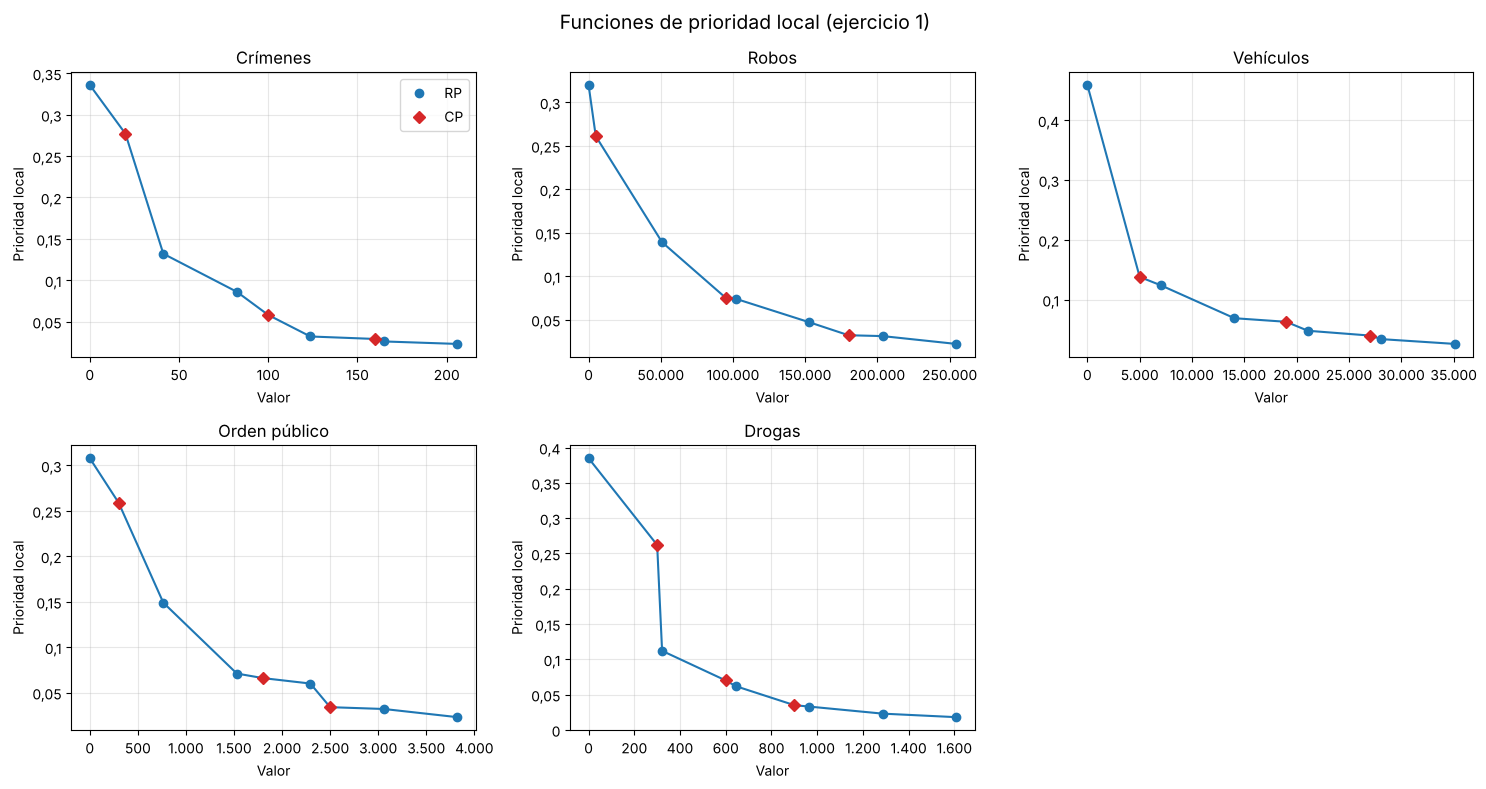

In [6]:
CP_EJ1 = pd.DataFrame({'Crímenes': [20, 100, 160], 'Robos': [5000, 95000, 180000],
                       'Vehículos': [5000, 19000, 27000], 'Orden público': [300, 1800, 2500],
                       'Drogas': [300, 600, 900]}, index=['CP1', 'CP2', 'CP3'])
MAXIMOS_EJ1 = {'Crímenes': 206, 'Robos': 254572, 'Vehículos': 35127, 'Orden público': 3824, 'Drogas': 1608}
RP_EJ1 = pd.DataFrame({c: puntos_referencia(MAXIMOS_EJ1[c]) for c in CRITERIOS},
                      index=[f'RP{i}' for i in range(1, 7)])
# Prioridades del cuestionario (Tabla 6), de menor a mayor valor
PRIORIDADES_EJ1 = {'Crímenes':      [0.336, 0.277, 0.132, 0.086, 0.058, 0.032, 0.029, 0.026, 0.023],
                   'Robos':         [0.320, 0.261, 0.139, 0.075, 0.074, 0.047, 0.032, 0.031, 0.022],
                   'Vehículos':     [0.459, 0.138, 0.124, 0.069, 0.063, 0.048, 0.040, 0.034, 0.026],
                   'Orden público': [0.308, 0.259, 0.149, 0.071, 0.066, 0.060, 0.034, 0.032, 0.023],
                   'Drogas':        [0.385, 0.262, 0.112, 0.070, 0.062, 0.035, 0.033, 0.023, 0.018]}

funciones_ej1 = {}
for c in CRITERIOS:
    f = funcion(list(RP_EJ1[c]) + list(CP_EJ1[c]), 0, list(RP_EJ1.index) + list(CP_EJ1.index))
    f['Prioridad'] = PRIORIDADES_EJ1[c]
    funciones_ej1[c] = f

mostrar(CP_EJ1.T, 0, 'Tabla 3. Perfiles centrales')
mostrar(RP_EJ1.T, 1, 'Tabla 5. Puntos de referencia')
display(Markdown('**Tabla 6. Puntos de las funciones de prioridad local (ordenados por valor)**'))
for c in CRITERIOS:
    mostrar_funcion(funciones_ej1[c], c)
dibujar_funciones(funciones_ej1, 'Funciones de prioridad local (ejercicio 1)', 'ej1_funciones.png')

### 2.4. Prioridades de los perfiles centrales (Tabla 7) y clasificación

**Tabla 7. Prioridades locales y globales de los perfiles centrales**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 (Alto),"0,2770","0,2610","0,1380","0,2590","0,2620","0,2618"
CP2 (Medio),"0,0580","0,0750","0,0630","0,0660","0,0700","0,0640"
CP3 (Bajo),"0,0290","0,0320","0,0400","0,0340","0,0350","0,0321"


Límites entre niveles: Alto si global > 0,1629; Medio entre 0,0480 y 0,1629; Bajo si < 0,0480


**Clasificación de las provincias andaluzas (datos absolutos)**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Almería,"0,2565","0,2284","0,3241","0,2384","0,2755","0,2611",Alto
Cádiz,"0,1099","0,2037","0,2057","0,1591","0,0436","0,1099",Medio
Córdoba,"0,2770","0,2357","0,3504","0,2722","0,3243","0,2904",Alto
Granada,"0,1949","0,2234","0,3114","0,2429","0,0659","0,1731",Alto
Huelva,"0,3124","0,2445","0,3685","0,2825","0,3280","0,3109",Alto
Jaén,"0,2859","0,2542","0,4129","0,2794","0,3321","0,3025",Alto
Málaga,"0,1132","0,1517","0,1285","0,1424","0,0340","0,0984",Medio
Sevilla,"0,0803","0,1362","0,1034","0,1605","0,0979","0,1004",Medio


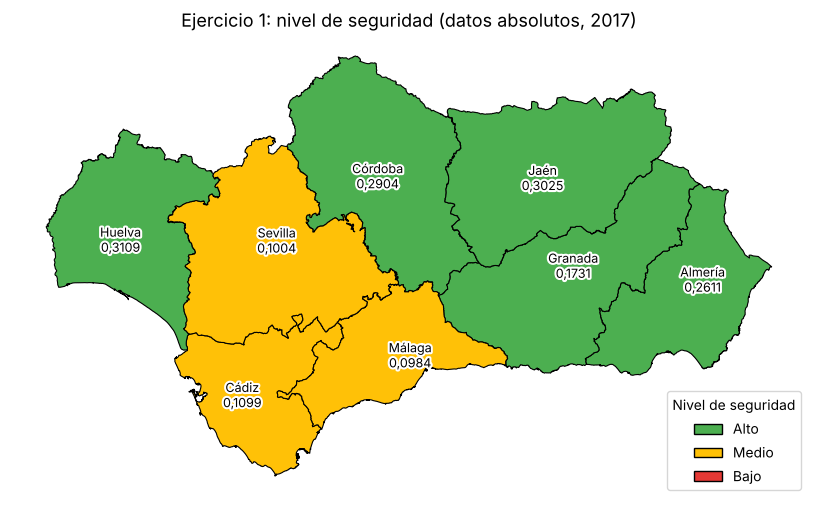

In [7]:
tabla7 = tabla_perfiles(funciones_ej1, CP_EJ1, pesos)
mostrar(tabla7, 4, 'Tabla 7. Prioridades locales y globales de los perfiles centrales')
cp_global_ej1 = tabla7['Global'].tolist()
l = limites(cp_global_ej1)
print(f'Límites entre niveles: Alto si global > {l[0]:.4f}; '
      f'Medio entre {l[1]:.4f} y {l[0]:.4f}; Bajo si < {l[1]:.4f}'.replace('.', ','))

res_ej1 = clasificar(datos_ej1, pesos, funciones_ej1, cp_global_ej1)
mostrar(res_ej1, 4, 'Clasificación de las provincias andaluzas (datos absolutos)')
res_ej1.to_csv('resultados/ej1_clasificacion.csv', sep=';', decimal=',')

fig, eje = plt.subplots(figsize=(11, 6))
mapa_andaluz(eje, res_ej1, 'Ejercicio 1: nivel de seguridad (datos absolutos, 2017)')
fig.savefig('resultados/ej1_mapa.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Ejercicio 2: Andalucía con datos por cada 10.000 habitantes
### 3.1. Normalización
Los datos absolutos dependen del tamaño de la provincia: una provincia con el doble de habitantes tiene, en general, el doble de delitos sin ser más insegura. Por eso se dividen entre la población y se expresan por cada 10.000 habitantes, con la población de `habitantes.xlsx`:

tasa = hechos / habitantes × 10.000

In [8]:
# ============================================================
# 3. EJERCICIO 2
# ============================================================
habitantes = pd.read_excel('datos/habitantes.xlsx', header=1).iloc[:, 1:]
habitantes.columns = ['Provincia', 'Habitantes']
habitantes = habitantes.set_index('Provincia')['Habitantes']

datos_ej2 = datos_ej1.div(habitantes[datos_ej1.index], axis=0) * 10000
tabla_hab = datos_ej2.copy()
tabla_hab.insert(0, 'Habitantes', habitantes[datos_ej1.index])
mostrar(tabla_hab, 2, 'Hechos delictivos por cada 10.000 habitantes (Andalucía, 2017)')

**Hechos delictivos por cada 10.000 habitantes (Andalucía, 2017)**

,Habitantes,Crímenes,Robos,Vehículos,Orden público,Drogas
Almería,731.792,"0,31","236,19","28,71","5,29","3,65"
Cádiz,1.245.960,"0,49","213,26","31,66","5,79","6,57"
Córdoba,776.789,"0,26","186,77","21,77","2,82","1,91"
Granada,921.338,"0,35","207,73","24,95","3,99","6,75"
Huelva,525.835,"0,15","213,41","26,80","2,97","2,64"
Jaén,627.190,"0,27","120,35","11,45","2,79","2,06"
Málaga,1.695.651,"0,34","272,09","37,61","4,89","5,51"
Sevilla,1.947.852,"0,44","271,32","49,60","3,68","2,13"


### 3.2. Perfiles centrales (Tabla 8), puntos de referencia (Tabla 9) y funciones de prioridad local (Tabla 10)
- **CP:** percentiles 20 (CP1, nivel Alto), 50 (CP2, nivel Medio) y 80 (CP3, nivel Bajo) de las tasas andaluzas.
- **RP:** 6 puntos entre 0 y la tasa máxima de Andalucía.
- **Prioridades:** los RP conservan las prioridades de los RP del ejercicio 1 (misma posición relativa en el rango), y las de los CP se obtienen por interpolación en esa función.

**Tabla 8. CPs recalculados (Andalucía, por cada 10.000 habitantes)**

,CP1,CP2,CP3
Crímenes,"0,26","0,33","0,40"
Robos,"195,15","213,34","257,27"
Vehículos,"23,04","27,75","35,23"
Orden público,"2,88","3,84","5,13"
Drogas,"2,09","3,15","6,14"


**Tabla 9. RPs recalculados**

,RP1,RP2,RP3,RP4,RP5,RP6
Crímenes,"0,00","0,10","0,20","0,29","0,39","0,49"
Robos,"0,00","54,42","108,84","163,25","217,67","272,09"
Vehículos,"0,00","9,92","19,84","29,76","39,68","49,60"
Orden público,"0,00","1,16","2,32","3,48","4,64","5,79"
Drogas,"0,00","1,35","2,70","4,05","5,40","6,75"


**Comparación con las Tablas 8 y 9 del enunciado**

,CP1 (Tabla 8),CP1 calculado,CP2 (Tabla 8),CP2 calculado,CP3 (Tabla 8),CP3 calculado,RP6 (Tabla 9),RP6 calculado
Crímenes,"0,26","0,26","0,34","0,33","0,41","0,40","0,49","0,49"
Robos,"194,29","195,15","215,32","213,34","261,32","257,27","282,94","272,09"
Vehículos,"22,95","23,04","28,44","27,75","36,20","35,23","49,82","49,60"
Orden público,"2,87","2,88","3,86","3,84","5,32","5,13","5,83","5,79"
Drogas,"2,06","2,09","3,23","3,15","6,25","6,14","6,81","6,75"


... (8 outputs left out)

**Orden público**

Punto,RP1,RP2,RP3,CP1,RP4,CP2,RP5,CP3,RP6
Valor,0,"1,159","2,318","2,878","3,477","3,835","4,636","5,131","5,795"
Prioridad,"0,308","0,149","0,071","0,066","0,060","0,051","0,032","0,028","0,023"


**Drogas**

Punto,RP1,RP2,CP1,RP3,CP2,RP4,RP5,CP3,RP6
Valor,0,"1,35","2,086","2,7","3,146","4,051","5,401","6,142","6,751"
Prioridad,"0,385","0,112","0,085","0,062","0,052","0,033","0,023","0,020","0,018"


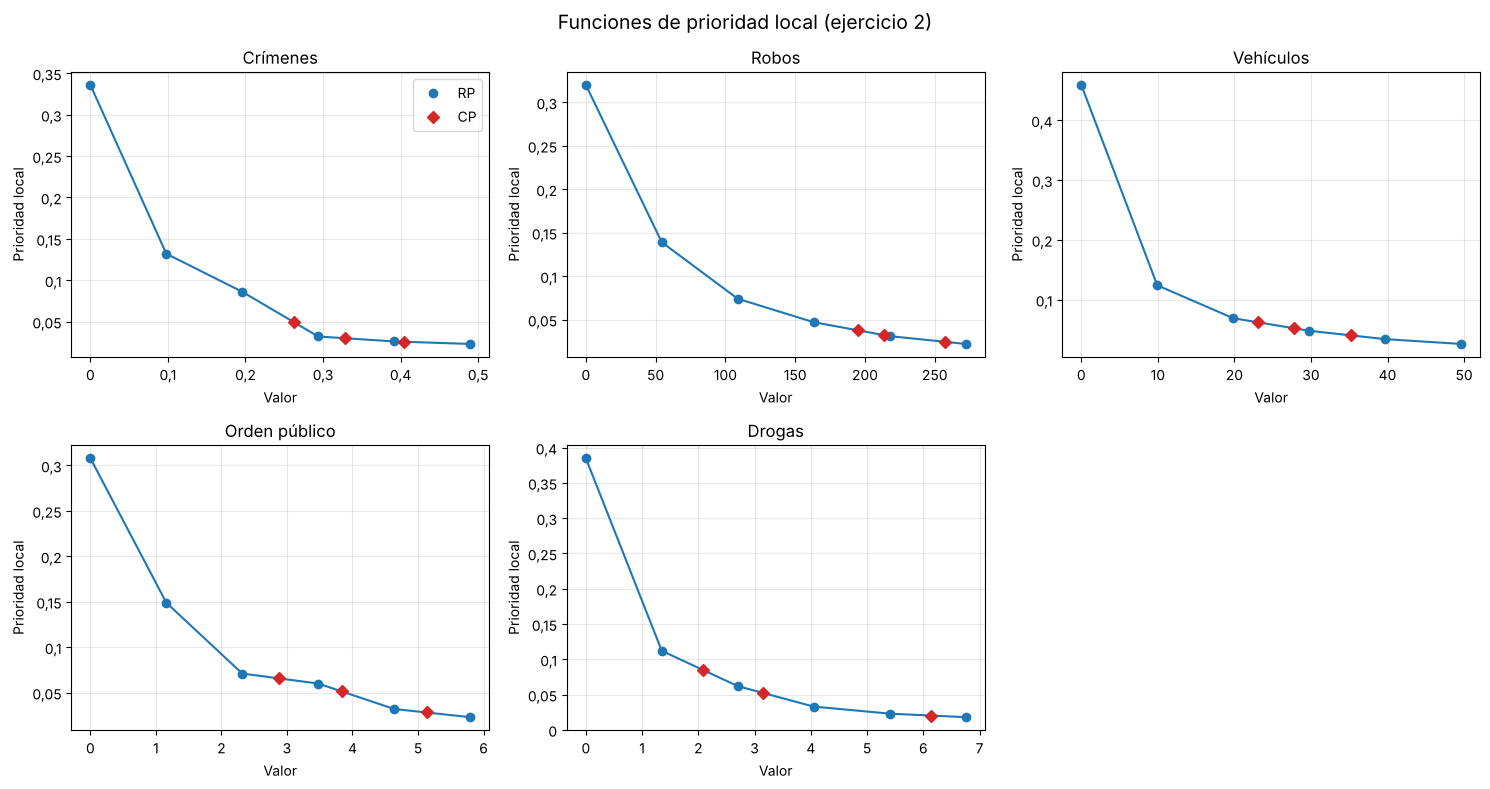

In [9]:
# Prioridades de los RP del ejercicio 1 (se reutilizan en los ejercicios 2, 3 y 4)
PRIORIDADES_RP = {c: [prioridad_local(funciones_ej1[c], x) for x in RP_EJ1[c]] for c in CRITERIOS}


def calibrar(tasas):
    """CPs, RPs y funciones de prioridad local a partir de unas tasas."""
    cps = pd.DataFrame({c: perfiles_centrales(tasas[c]) for c in CRITERIOS}, index=['CP1', 'CP2', 'CP3'])
    rps = pd.DataFrame({c: puntos_referencia(tasas[c].max()) for c in CRITERIOS},
                       index=[f'RP{i}' for i in range(1, 7)])
    funciones = {}
    for c in CRITERIOS:
        solo_rp = funcion(rps[c], PRIORIDADES_RP[c], rps.index)
        prior_cp = [prioridad_local(solo_rp, x) for x in cps[c]]
        funciones[c] = funcion(list(rps[c]) + list(cps[c]), PRIORIDADES_RP[c] + prior_cp,
                               list(rps.index) + list(cps.index))
    return cps, rps, funciones


cp_ej2, rp_ej2, funciones_ej2 = calibrar(datos_ej2)
mostrar(cp_ej2.T, 2, 'Tabla 8. CPs recalculados (Andalucía, por cada 10.000 habitantes)')
mostrar(rp_ej2.T, 2, 'Tabla 9. RPs recalculados')

# Comparación con las Tablas 8 y 9 del enunciado
TABLA8 = pd.DataFrame({'Crímenes': [0.26, 0.34, 0.41], 'Robos': [194.29, 215.32, 261.32],
                       'Vehículos': [22.95, 28.44, 36.20], 'Orden público': [2.87, 3.86, 5.32],
                       'Drogas': [2.06, 3.23, 6.25]}, index=['CP1', 'CP2', 'CP3'])
TABLA9_RP6 = pd.Series({'Crímenes': 0.49, 'Robos': 282.94, 'Vehículos': 49.82, 'Orden público': 5.83, 'Drogas': 6.81})
comparacion = pd.DataFrame({'CP1 (Tabla 8)': TABLA8.loc['CP1'], 'CP1 calculado': cp_ej2.loc['CP1'],
                            'CP2 (Tabla 8)': TABLA8.loc['CP2'], 'CP2 calculado': cp_ej2.loc['CP2'],
                            'CP3 (Tabla 8)': TABLA8.loc['CP3'], 'CP3 calculado': cp_ej2.loc['CP3'],
                            'RP6 (Tabla 9)': TABLA9_RP6, 'RP6 calculado': rp_ej2.loc['RP6']})
mostrar(comparacion, 2, 'Comparación con las Tablas 8 y 9 del enunciado')
print('Las pequeñas diferencias se deben a que habitantes.xlsx no es la población de 2017 (ver ejercicio 3).')

display(Markdown('**Tabla 10. Puntos de las funciones de prioridad local (ordenados por valor)**'))
for c in CRITERIOS:
    mostrar_funcion(funciones_ej2[c], c)
dibujar_funciones(funciones_ej2, 'Funciones de prioridad local (ejercicio 2)', 'ej2_funciones.png')

### 3.3. Clasificación
Se reutilizan los pesos de los criterios del ejercicio 1.

**Prioridades locales y globales de los perfiles centrales**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 (Alto),"0,0490","0,0376","0,0622","0,0657","0,0847","0,0608"
CP2 (Medio),"0,0299","0,0323","0,0523","0,0513","0,0524","0,0401"
CP3 (Bajo),"0,0256","0,0245","0,0403","0,0282","0,0203","0,0251"


**Clasificación de las provincias andaluzas (por cada 10.000 habitantes)**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Almería,"0,0307","0,0279","0,0502","0,0269","0,0416","0,0342",Medio
Cádiz,"0,0230","0,0323","0,0453","0,0230","0,0187","0,0238",Bajo
Córdoba,"0,0520","0,0401","0,0649","0,0662","0,0914","0,0645",Alto
Granada,"0,0287","0,0339","0,0582","0,0475","0,0180","0,0299",Bajo
Huelva,"0,1065","0,0323","0,0543","0,0648","0,0641","0,0809",Alto
Jaén,"0,0445","0,0683","0,1155","0,0665","0,0858","0,0645",Alto
Málaga,"0,0290","0,0220","0,0369","0,0300","0,0226","0,0272",Bajo
Sevilla,"0,0245","0,0221","0,0260","0,0552","0,0831","0,0444",Medio


**Comparación de las dos clasificaciones**

,Ejercicio 1 (absolutos),Ejercicio 2 (por 10.000 hab.)
Almería,Alto,Medio
Cádiz,Medio,Bajo
Córdoba,Alto,Alto
Granada,Alto,Bajo
Huelva,Alto,Alto
Jaén,Alto,Alto
Málaga,Medio,Bajo
Sevilla,Medio,Medio


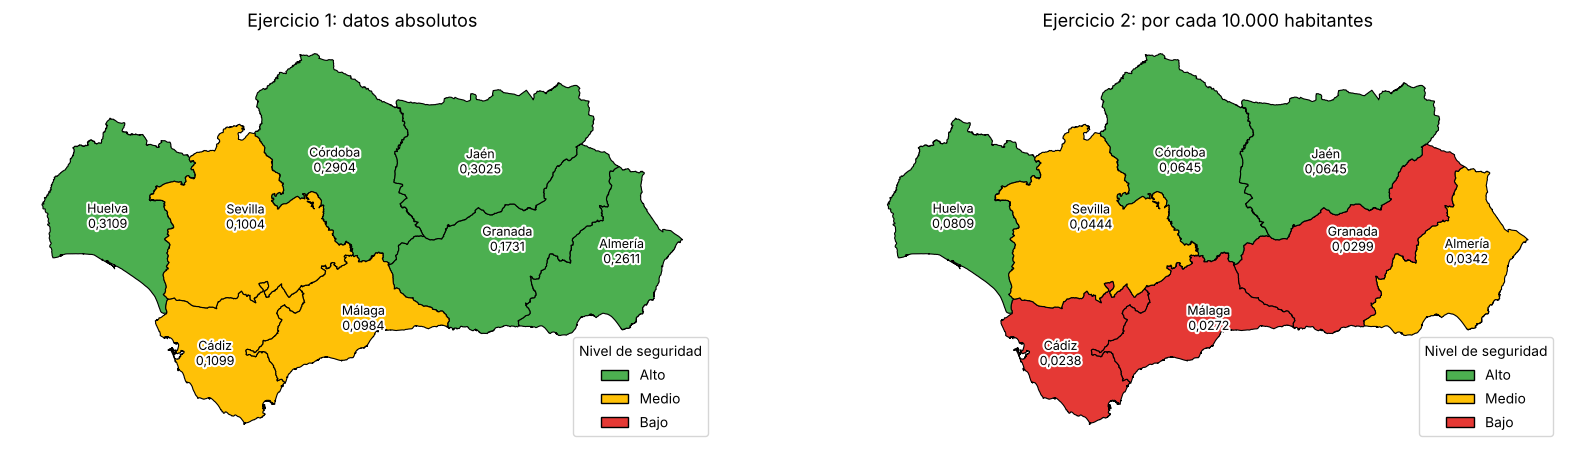

In [10]:
tabla_cp_ej2 = tabla_perfiles(funciones_ej2, cp_ej2, pesos)
mostrar(tabla_cp_ej2, 4, 'Prioridades locales y globales de los perfiles centrales')
cp_global_ej2 = tabla_cp_ej2['Global'].tolist()

res_ej2 = clasificar(datos_ej2, pesos, funciones_ej2, cp_global_ej2)
mostrar(res_ej2, 4, 'Clasificación de las provincias andaluzas (por cada 10.000 habitantes)')
res_ej2.to_csv('resultados/ej2_clasificacion.csv', sep=';', decimal=',')

cambio = pd.DataFrame({'Ejercicio 1 (absolutos)': res_ej1['Nivel de seguridad'],
                       'Ejercicio 2 (por 10.000 hab.)': res_ej2['Nivel de seguridad']})
mostrar(cambio, 0, 'Comparación de las dos clasificaciones')

fig, ejes = plt.subplots(1, 2, figsize=(20, 6))
mapa_andaluz(ejes[0], res_ej1, 'Ejercicio 1: datos absolutos')
mapa_andaluz(ejes[1], res_ej2, 'Ejercicio 2: por cada 10.000 habitantes')
fig.savefig('resultados/ej2_mapa.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Ejercicio 3: España (50 provincias), 2017
### 4.1. Datos y verificación de la normalización (actividad a)
El fichero `Datos_nacionales_2017_por_10000_ES.xlsx` ya contiene las tasas por cada 10.000 habitantes de las 50 provincias (sin Ceuta ni Melilla).

Para verificarlo, se comparan con los datos absolutos de Andalucía: la población que resulta de dividir los hechos entre la tasa es la misma para los cinco criterios de cada provincia, y corresponde a la población de 2017. Por eso las tasas coinciden con las del ejercicio 2 salvo pequeñas diferencias: `habitantes.xlsx` es de otro año.

In [11]:
# ============================================================
# 4. EJERCICIO 3
# ============================================================
nac17 = pd.read_excel('datos/Datos_nacionales_2017_por_10000_ES.xlsx')
nac17.columns = ['Provincia'] + CRITERIOS
nac17['Provincia'] = nac17['Provincia'].replace(NOMBRES)
datos_ej3 = nac17.set_index('Provincia')
print('Provincias:', len(datos_ej3), '| valores negativos:', int((datos_ej3 < 0).sum().sum()),
      '| valores vacíos:', int(datos_ej3.isna().sum().sum()))

poblacion = (datos_ej1 / datos_ej3.loc[datos_ej1.index] * 10000).replace([np.inf], np.nan)
verif = pd.DataFrame({'Población implícita (mín.)': poblacion.min(axis=1),
                      'Población implícita (máx.)': poblacion.max(axis=1),
                      'habitantes.xlsx': habitantes[datos_ej1.index]})
verif['Diferencia (%)'] = (verif['habitantes.xlsx'] / verif['Población implícita (máx.)'] - 1) * 100
verif[verif.columns[:3]] = verif[verif.columns[:3]].round().astype(int)
mostrar(verif, 1, 'Verificación: población usada en el fichero nacional (Andalucía)')
mostrar((datos_ej2 - datos_ej3.loc[datos_ej2.index]), 2,
        'Diferencia entre las tasas del ejercicio 2 y las del fichero nacional')

Provincias: 50 | valores negativos: 0 | valores vacíos: 0


**Verificación: población usada en el fichero nacional (Andalucía)**

,Población implícita (mín.),Población implícita (máx.),habitantes.xlsx,Diferencia (%)
Almería,706.672,706.672,731.792,"3,6"
Cádiz,1.239.435,1.239.435,1.245.960,"0,5"
Córdoba,788.219,788.219,776.789,"-1,5"
Granada,912.938,912.938,921.338,"0,9"
Huelva,518.930,518.930,525.835,"1,3"
Jaén,643.484,643.484,627.190,"-2,5"
Málaga,1.630.615,1.630.615,1.695.651,"4,0"
Sevilla,1.939.527,1.939.527,1.947.852,"0,4"


**Diferencia entre las tasas del ejercicio 2 y las del fichero nacional**

,Crímenes,Robos,Vehículos,Orden público,Drogas
Almería,"-0,01","-8,40","-1,02","-0,19","-0,13"
Cádiz,"0,00","-1,12","-0,17","-0,03","-0,03"
Córdoba,"0,00","2,71","0,32","0,04","0,03"
Granada,"0,00","-1,91","-0,23","-0,04","-0,06"
Huelva,"0,00","-2,84","-0,36","-0,04","-0,04"
Jaén,"0,01","3,05","0,29","0,07","0,05"
Málaga,"-0,01","-10,85","-1,50","-0,20","-0,22"
Sevilla,"0,00","-1,16","-0,21","-0,02","-0,01"


### 4.2. Perfiles centrales y puntos de referencia nacionales (actividad b)
Se calculan con el mismo criterio que en el ejercicio 2, ahora con las 50 provincias:
- **CP1, CP2 y CP3:** percentiles 20, 50 y 80. CP1 deja por debajo al 20 % de las provincias (las de menos delitos), CP2 es la mediana y CP3 deja por encima al 20 % de las provincias (las de más delitos). Así, cada perfil representa a una provincia típica de su nivel.
- **RP:** 6 puntos equidistantes entre 0 y la tasa máxima nacional, para cubrir todo el rango de valores.
- **Prioridades de los RP:** se heredan del ejercicio 1 (Tabla 13). Las de los CP se obtienen por interpolación (Tabla 14).

**Tabla 11. Perfiles centrales nacionales (por cada 10.000 habitantes)**

,CP1,CP2,CP3
Crímenes,"0,17","0,25","0,36"
Robos,"129,18","179,37","268,99"
Vehículos,"7,42","13,69","30,94"
Orden público,"2,73","3,38","4,52"
Drogas,"1,46","2,00","2,77"


**Tabla 12. Puntos de referencia nacionales**

,RP1,RP2,RP3,RP4,RP5,RP6
Crímenes,"0,00","0,15","0,30","0,44","0,59","0,74"
Robos,"0,00","81,29","162,59","243,88","325,17","406,46"
Vehículos,"0,00","10,80","21,59","32,39","43,19","53,98"
Orden público,"0,00","1,18","2,35","3,53","4,70","5,88"
Drogas,"0,00","1,36","2,73","4,09","5,45","6,81"


**Tabla 13. Prioridades locales de los RP**

,Crímenes,Robos,Vehículos,Orden público,Drogas
RP1,"0,336","0,320","0,459","0,308","0,385"
RP2,"0,132","0,139","0,124","0,149","0,112"
RP3,"0,086","0,074","0,069","0,071","0,062"
RP4,"0,032","0,047","0,048","0,060","0,033"
RP5,"0,026","0,031","0,034","0,032","0,023"
RP6,"0,023","0,022","0,026","0,023","0,018"


**Tabla 14. Prioridades locales y globales de los perfiles centrales**

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
CP1 (Alto),"0,125","0,101","0,229","0,067","0,109","0,118"
CP2 (Medio),"0,099","0,068","0,109","0,061","0,089","0,090"
CP3 (Bajo),"0,061","0,042","0,051","0,036","0,061","0,056"


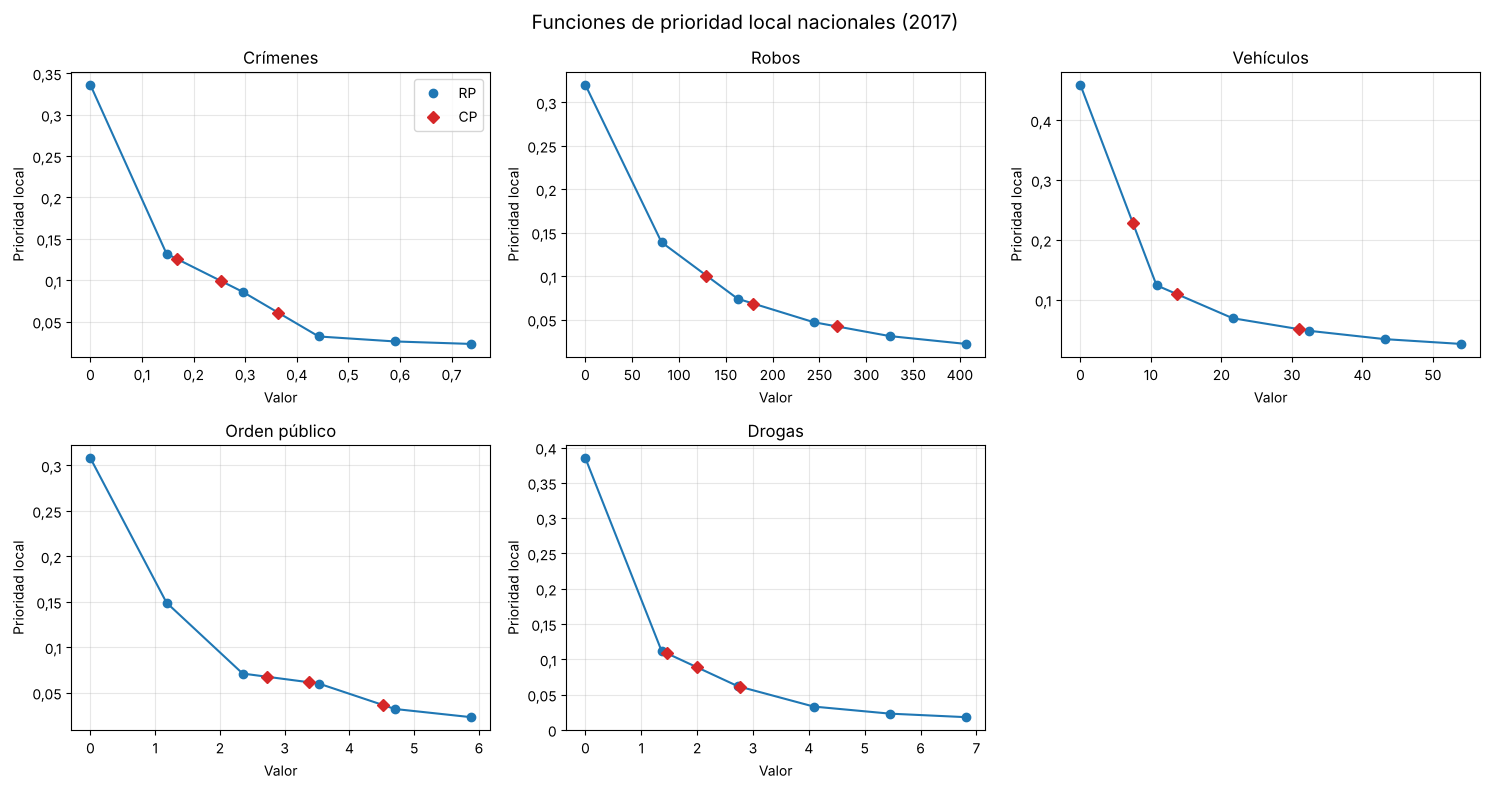

In [12]:
cp_ej3, rp_ej3, funciones_ej3 = calibrar(datos_ej3)
mostrar(cp_ej3.T, 2, 'Tabla 11. Perfiles centrales nacionales (por cada 10.000 habitantes)')
mostrar(rp_ej3.T, 2, 'Tabla 12. Puntos de referencia nacionales')
mostrar(pd.DataFrame(PRIORIDADES_RP, index=rp_ej3.index), 3, 'Tabla 13. Prioridades locales de los RP')
tabla14 = tabla_perfiles(funciones_ej3, cp_ej3, pesos)
mostrar(tabla14, 3, 'Tabla 14. Prioridades locales y globales de los perfiles centrales')
cp_global_ej3 = tabla14['Global'].tolist()
dibujar_funciones(funciones_ej3, 'Funciones de prioridad local nacionales (2017)', 'ej3_funciones.png')

### 4.3. Clasificación de las provincias españolas

**Clasificación de las 50 provincias (2017)**

Provincia,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Soria,"0,3360","0,1019","0,2286","0,1001","0,1371","0,2278",Alto
Palencia,"0,3360","0,1212","0,3375","0,0536","0,1059","0,2211",Alto
Burgos,"0,2974","0,0776","0,1140","0,0462","0,0862","0,1809",Alto
Cuenca,"0,2664","0,0768","0,1054","0,1034","0,0992","0,1763",Alto
Lugo,"0,2117","0,1247","0,1558","0,0686","0,1070","0,1555",Alto
Valladolid,"0,0816","0,0718","0,1756","0,0793","0,2735","0,1395",Alto
León,"0,1114","0,0723","0,1271","0,0664","0,2139","0,1326",Alto
Segovia,"0,1566","0,1030","0,2618","0,0639","0,0977","0,1307",Alto
Ávila,"0,1639","0,1004","0,2215","0,0633","0,0844","0,1279",Alto
Guadalajara,"0,1722","0,0654","0,0641","0,0612","0,1084","0,1268",Alto


Provincias por nivel: Alto: 20 · Medio: 13 · Bajo: 17


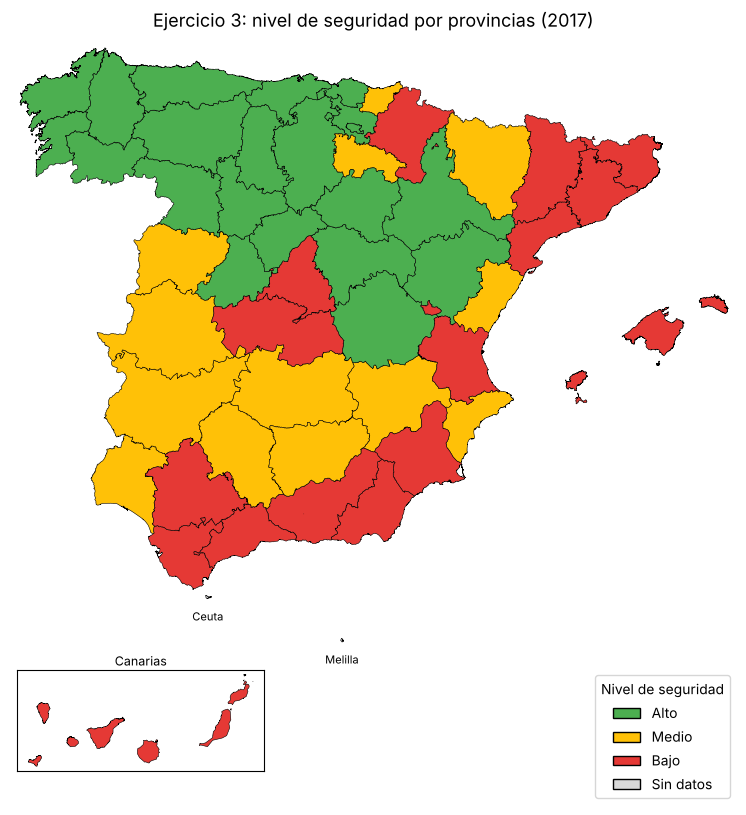

In [13]:
res_ej3 = clasificar(datos_ej3, pesos, funciones_ej3, cp_global_ej3)
res_ej3 = res_ej3.sort_values('Global', ascending=False)
mostrar(res_ej3, 4, 'Clasificación de las 50 provincias (2017)')
recuento = res_ej3['Nivel de seguridad'].value_counts().reindex(NIVELES, fill_value=0)
print('Provincias por nivel:', ' · '.join(f'{n}: {k}' for n, k in recuento.items()))
res_ej3.to_csv('resultados/ej3_clasificacion.csv', sep=';', decimal=',')

fig, eje = plt.subplots(figsize=(12, 10))
mapa_espanol(eje, res_ej3, 'Ejercicio 3: nivel de seguridad por provincias (2017)')
fig.savefig('resultados/ej3_mapa.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Ejercicio 4: España, 2023, con la calibración de 2017
Se mantienen los pesos, los CP, los RP y las funciones de prioridad local de 2017 (ejercicio 3). Las tasas de 2023 que superan el último punto de referencia (RP6) se **truncan**: reciben la prioridad de RP6.

In [14]:
# ============================================================
# 5. EJERCICIO 4
# ============================================================
nac23 = pd.read_excel('datos/Datos_nacionales_2023_por_10000_ES.xlsx', sheet_name='Datos 2023')
nac23['Provincia'] = nac23['Provincia'].replace(NOMBRES)
nac23 = nac23.set_index('Provincia')
datos_ej4 = nac23[CRITERIOS]

# Verificación: tasa = hechos / población × 10.000
abs23 = nac23[['Abs ' + c for c in CRITERIOS]].to_numpy()
recalculo = abs23 / nac23[['Población 2023']].to_numpy() * 10000
print('Tasas 2023 = hechos / población × 10.000:', 'Sí' if np.allclose(recalculo, datos_ej4.to_numpy()) else 'No')

# Truncamiento
fuera = []
for c in CRITERIOS:
    for p, x in datos_ej4[c].items():
        if x > rp_ej3.loc['RP6', c]:
            fuera.append({'Provincia': p, 'Criterio': c, 'Tasa 2023': x, 'RP6 (2017)': rp_ej3.loc['RP6', c]})
mostrar(pd.DataFrame(fuera).set_index('Provincia'), 2, f'Tasas truncadas a RP6 ({len(fuera)})')

res_ej4 = clasificar(datos_ej4, pesos, funciones_ej3, cp_global_ej3)
res_ej4 = res_ej4.sort_values('Global', ascending=False)
mostrar(res_ej4, 4, 'Clasificación de las 50 provincias (2023)')
recuento = res_ej4['Nivel de seguridad'].value_counts().reindex(NIVELES, fill_value=0)
print('Provincias por nivel:', ' · '.join(f'{n}: {k}' for n, k in recuento.items()))
res_ej4.to_csv('resultados/ej4_clasificacion.csv', sep=';', decimal=',')

Tasas 2023 = hechos / población × 10.000: Sí


**Tasas truncadas a RP6 (20)**

Provincia,Criterio,Tasa 2023,RP6 (2017)
Alicante/Alacant,Orden público,"8,33","5,88"
Almería,Orden público,"8,61","5,88"
Araba/Álava,Orden público,"6,86","5,88"
Illes Balears,Orden público,"7,63","5,88"
Cádiz,Orden público,"8,08","5,88"
Castellón/Castelló,Orden público,"6,77","5,88"
Gipuzkoa,Orden público,"7,17","5,88"
Girona,Orden público,"6,52","5,88"
Madrid,Orden público,"8,32","5,88"
Málaga,Orden público,"7,86","5,88"


**Clasificación de las 50 provincias (2023)**

Provincia,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,Nivel de seguridad
Teruel,"0,2338","0,1713","0,3580","0,0667","0,0915","0,1761",Alto
Ourense,"0,1998","0,1265","0,1138","0,0501","0,1613","0,1608",Alto
Segovia,"0,2469","0,1254","0,1932","0,0241","0,0583","0,1552",Alto
Burgos,"0,1812","0,1023","0,1204","0,0241","0,0778","0,1241",Alto
Cáceres,"0,1297","0,1425","0,2940","0,0621","0,0796","0,1178",Alto
Bizkaia,"0,1324","0,0551","0,3426","0,0247","0,0937","0,1142",Alto
Salamanca,"0,1304","0,0988","0,0904","0,0615","0,0869","0,1054",Alto
Asturias,"0,1129","0,1190","0,1982","0,0291","0,0926","0,1026",Medio
Zamora,"0,1218","0,1306","0,2706","0,0566","0,0484","0,1025",Medio
Cantabria,"0,1250","0,0969","0,1284","0,0314","0,0909","0,1024",Medio


Provincias por nivel: Alto: 7 · Medio: 19 · Bajo: 24


### 5.1. Mapas de 2017 y 2023 (misma leyenda)

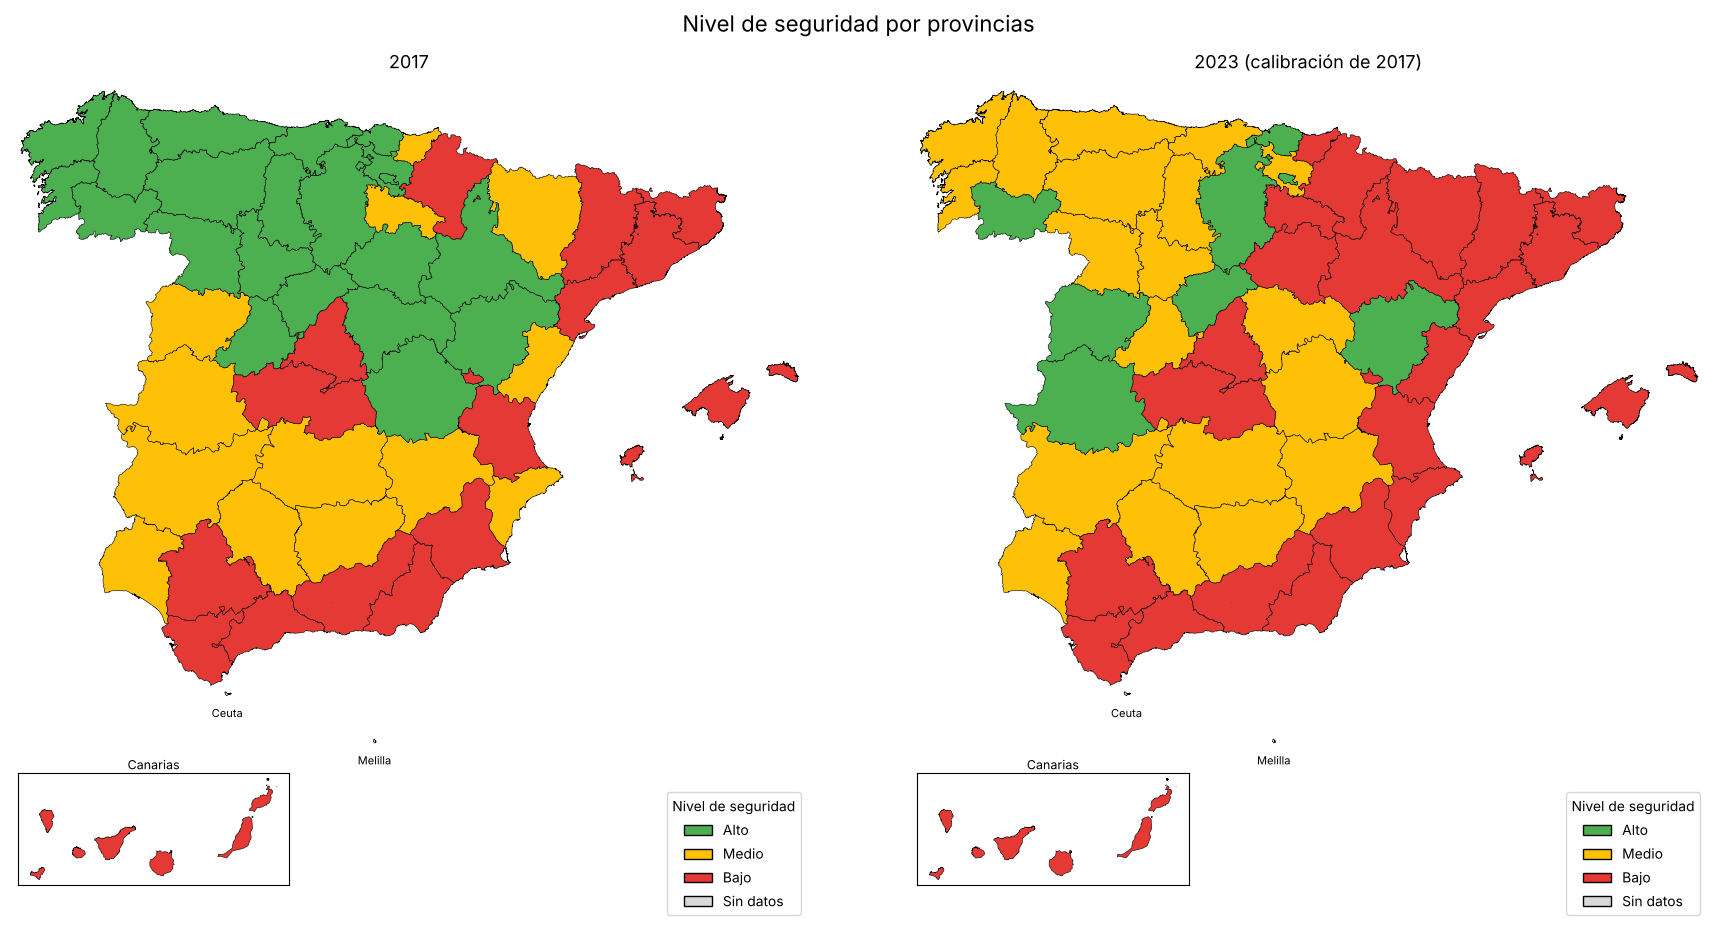

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(18, 9.5))
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.9, wspace=0.04)
mapa_espanol(ejes[0], res_ej3, '2017')
mapa_espanol(ejes[1], res_ej4, '2023 (calibración de 2017)')
fig.suptitle('Nivel de seguridad por provincias', fontsize=16, y=0.97)
fig.savefig('resultados/ej4_mapas_2017_2023.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2. Tabla de transición por provincias y matriz de cambios
- **Tabla de transición:** nivel de cada provincia en 2017 y en 2023. *Mejora* significa que sube a un nivel de seguridad más alto (por ejemplo, de Medio a Alto) y *Empeora* que baja (por ejemplo, de Alto a Medio).
- **Matriz de cambios:** las filas son el nivel de 2017 y las columnas el de 2023. Cada casilla cuenta las provincias que pasan de un nivel a otro; la diagonal son las que no cambian.

In [16]:
orden = {n: i for i, n in enumerate(NIVELES)}
transicion = pd.DataFrame({'2017': res_ej3['Nivel de seguridad'], '2023': res_ej4['Nivel de seguridad'],
                           'Global 2017': res_ej3['Global'], 'Global 2023': res_ej4['Global']})
transicion['Cambio'] = [('Igual' if a == b else 'Mejora' if orden[b] < orden[a] else 'Empeora')
                        for a, b in zip(transicion['2017'], transicion['2023'])]
transicion = transicion.sort_index(key=lambda indice: indice.map(sin_tildes))
transicion.index.name = 'Provincia'
mostrar(transicion, 4, 'Tabla de transición por provincias (2017 → 2023)')
transicion.to_csv('resultados/ej4_transicion.csv', sep=';', decimal=',')

matriz = pd.crosstab(transicion['2017'], transicion['2023'], margins=True, margins_name='Total')
matriz = matriz.reindex(index=NIVELES + ['Total'], columns=NIVELES + ['Total'], fill_value=0)
matriz = matriz.rename_axis(index=None, columns='2017 \\ 2023')    # filas: 2017; columnas: 2023
mostrar(matriz, 0, 'Matriz de cambios entre niveles')
matriz.to_csv('resultados/ej4_matriz_cambios.csv', sep=';', index_label='2017 \\ 2023')
recuento = transicion['Cambio'].value_counts().reindex(['Igual', 'Mejora', 'Empeora'], fill_value=0)
print('Provincias:', ' · '.join(f'{n}: {k}' for n, k in recuento.items()))

**Tabla de transición por provincias (2017 → 2023)**

Provincia,2017,2023,Global 2017,Global 2023,Cambio
A Coruña,Alto,Medio,"0,1197","0,0975",Empeora
Albacete,Medio,Medio,"0,0740","0,0736",Igual
Alicante/Alacant,Medio,Bajo,"0,0746","0,0399",Empeora
Almería,Bajo,Bajo,"0,0558","0,0336",Igual
Araba/Álava,Alto,Medio,"0,1142","0,0937",Empeora
Asturias,Alto,Medio,"0,1163","0,1026",Empeora
Ávila,Alto,Medio,"0,1279","0,0882",Empeora
Badajoz,Medio,Medio,"0,0877","0,0834",Igual
Barcelona,Bajo,Bajo,"0,0574","0,0409",Igual
Bizkaia,Alto,Alto,"0,1149","0,1142",Igual


**Matriz de cambios entre niveles**

2017 \ 2023,Alto,Medio,Bajo,Total
Alto,5,13,2,20
Medio,2,6,5,13
Bajo,0,0,17,17
Total,7,19,24,50


Provincias: Igual: 28 · Mejora: 2 · Empeora: 20
